In [1]:
import pandas as pd

In [2]:
# =========================================================
# 1. LOAD CLEANED DATASETS                                 
# =========================================================
df_web = pd.read_csv('02_cleaned_data_files/cleaned_web_events.csv')             
df_exp = pd.read_csv('02_cleaned_data_files/cleaned_clients_variation.csv')      
                                                           
                                                           
# Ensure date_time is in datetime format                   
df_web['date_time'] = pd.to_datetime(df_web['date_time'])  

In [3]:
# =========================================================                        
# 2. CALCULATE ERROR RATE (BACKWARD NAVIGATION)                                    
# =========================================================                        
                                                                                   
                                                                                   
# Step order mapping to detect going backward                                      
step_order = {                                                                     
    'start': 1,                                                                    
    'step_1': 2,                                                                   
    'step_2': 3,                                                                   
    'step_3': 4,                                                                   
    'confirm': 5                                                                   
}                                                                                  
                                                                                   
                                                                                   
# Map step names to numerical values                                               
df_web['step_number'] = df_web['process_step'].map(step_order)                     
                                                                                   
                                                                                   
# Sort events chronologically per session (visit_id)                               
df_web = df_web.sort_values(by=['visit_id', 'date_time'])                          
                                                                                   
                                                                                   
# Identify the previous step within the same visit session                         
df_web['previous_step_number'] = df_web.groupby('visit_id')['step_number'].shift(1)
                                                                                   
                                                                                   
# An error occurs when a user moves to an earlier step                             
df_web['is_error'] = df_web['step_number'] < df_web['previous_step_number']        

In [4]:
# =========================================================
# 3. OVERALL ERROR RATE                                    
# =========================================================
total_errors = df_web['is_error'].sum()                    
total_events = len(df_web)                                 
overall_error_rate = (total_errors / total_events) * 100   
                                                           
                                                           
print(f"Total Interactions: {total_events}")               
print(f"Total Errors (Backward Steps): {total_errors}")    
print(f"Overall Error Rate: {overall_error_rate:.2f}%\n") 
# =========================================================       
# 4. ERROR RATE BY EXPERIMENT GROUP (CONTROL VS TEST)             
# =========================================================       
# Merge with experiment data to compare Control vs Test           
df_web_exp = df_web.merge(df_exp, on='client_id', how='inner')    
                                                                  
                                                                  
error_by_group = df_web_exp.groupby('Variation').agg(             
    total_interactions=('is_error', 'count'),                     
    total_errors=('is_error', 'sum'),                             
    error_rate=('is_error', lambda x: (x.sum() / x.count()) * 100)
)                                                                 
                                                                  
                                                                  
print("--- Error Rate by Experiment Group ---")                   
print(error_by_group)                                             

Total Interactions: 317135
Total Errors (Backward Steps): 26033
Overall Error Rate: 8.21%

--- Error Rate by Experiment Group ---
           total_interactions  total_errors  error_rate
Variation                                              
Control                140494          9696    6.901362
Test                   176641         16337    9.248702


The error rate in the Test group (9.25%) is approximately 2.35 percentage points higher than in the Control group (6.90%).

What does this mean in practice?
Users interacting with the new design tend to navigate backward between steps more frequently than those using the old design. This could indicate greater navigation confusion within the interface or a specific step in the new process that is not entirely intuitive for the user.

In [5]:
# Group by Variation and process_step to calculate step-level error rates
step_error_by_group = df_web_exp.groupby(['Variation', 'process_step']).agg(
    total_interactions=('is_error', 'count'),
    total_errors=('is_error', 'sum'),
    error_rate=('is_error', lambda x: (x.sum() / x.count()) * 100)
).reset_index()

# Ensure process steps follow logical order
step_order_list = ['start', 'step_1', 'step_2', 'step_3', 'confirm']
step_error_by_group['process_step'] = pd.Categorical(
    step_error_by_group['process_step'], 
    categories=step_order_list, 
    ordered=True
)
step_error_by_group = step_error_by_group.sort_values(['Variation', 'process_step'])

print("Step-by-step error rates ready!")

Step-by-step error rates ready!


C:\Users\yurii\AppData\Local\Temp\ipykernel_16420\1545962884.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(


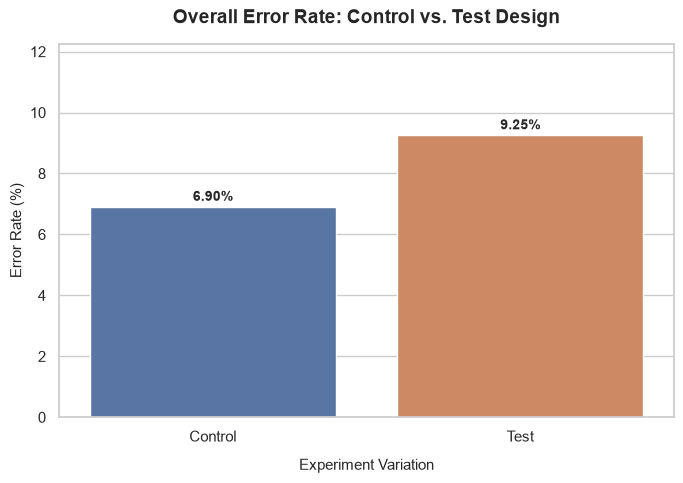

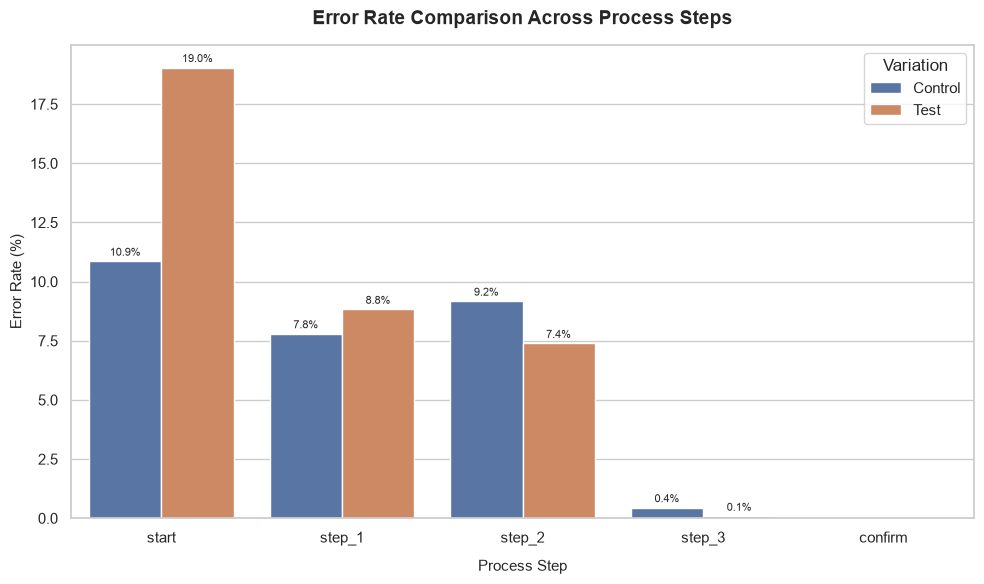

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")
custom_palette = {"Control": "#4C72B0", "Test": "#DD8452"}

# ---------------------------------------------------------
# CHART 1: Overall Error Rate (Control vs. Test)
# ---------------------------------------------------------
plt.figure(figsize=(7, 5))
ax1 = sns.barplot(
    data=error_by_group.reset_index(),
    x='Variation',
    y='error_rate',
    palette=custom_palette
)

plt.title('Overall Error Rate: Control vs. Test Design', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Experiment Variation', fontsize=11, labelpad=10)
plt.ylabel('Error Rate (%)', fontsize=11)
plt.ylim(0, max(error_by_group['error_rate']) + 3)

# Add data labels on top of bars
for p in ax1.patches:
    ax1.annotate(
        f'{p.get_height():.2f}%',
        (p.get_x() + p.get_width() / 2., p.get_height()),
        ha='center', va='center',
        xytext=(0, 7),
        textcoords='offset points',
        fontsize=10, fontweight='bold'
    )

plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# CHART 2: Error Rate Breakdown by Process Step
# ---------------------------------------------------------
plt.figure(figsize=(10, 6))
ax2 = sns.barplot(
    data=step_error_by_group,
    x='process_step',
    y='error_rate',
    hue='Variation',
    palette=custom_palette
)

plt.title('Error Rate Comparison Across Process Steps', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Process Step', fontsize=11, labelpad=10)
plt.ylabel('Error Rate (%)', fontsize=11)
plt.legend(title='Variation', frameon=True)

# Add data labels on top of bars
for p in ax2.patches:
    height = p.get_height()
    if pd.notnull(height) and height > 0:
        ax2.annotate(
            f'{height:.1f}%',
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='center',
            xytext=(0, 6),
            textcoords='offset points',
            fontsize=8
        )

plt.tight_layout()
plt.show()